**Project Title:-House Price Prediction**

**Aim:**-To develop a machine learning model that predicts house prices based on property features such as location, total area, number of bedrooms, bathrooms, and balcony availability.

**Problem Statement:**-House prices vary depending on several factors, including property size, location, and available facilities. Estimating an appropriate house price can be challenging for buyers and sellers. This project aims to develop a regression model that analyzes historical housing data and predicts house prices based on the given property details.

**Dataset:**-The dataset contains information about residential properties in Bangalore, including their location, size, area, number of bathrooms, balconies, and prices.

**Input Features:**-
The input features are the independent variables used to predict house prices.

-area_type – Type of property area.

-availability – Availability status of the property.

-location – Location of the house.

-total_sqft – Total area of the house in square feet.

-bath – Number of bathrooms.

-balcony – Number of balconies.

-bhk – Number of bedrooms, halls, and kitchens.

**Target Variable:**-
price – The selling price of the house.
The target is a continuous numerical variable, making this a supervised machine learning regression problem.

**Expected Outcome:**-
The project aims to develop a trained machine learning model that predicts house prices from property details. Different regression algorithms, such as Linear Regression, Decision Tree, Random Forest, and Gradient Boosting, can be compared using MAE, RMSE, and R² score to identify a suitable model.

**Step 1 — Import the libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Load the dataset
data=pd.read_csv("archive.zip")

**Step 2 — Data Understanding**

In [3]:
data.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [4]:
data.shape

(13320, 9)

In [5]:
data.columns #Column names

Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='object')

In [6]:
#Data types and missing values
data.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [7]:
#Statistical summary
data.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [8]:
#Missing values
data.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [9]:
#Duplicate rows
data.duplicated().sum()

np.int64(529)

**Step 3— Data Cleaning**

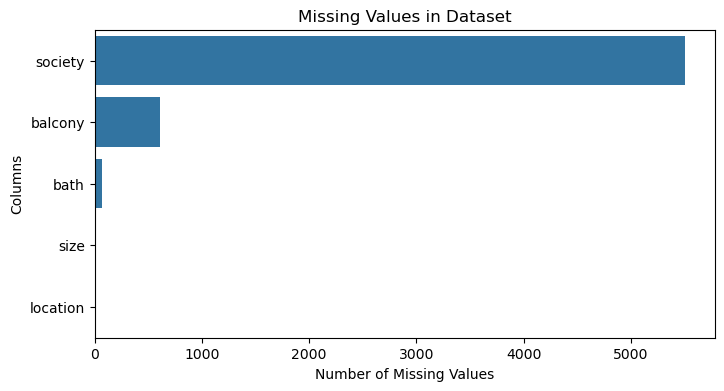

In [10]:
#Visualize missing values
import matplotlib.pyplot as plt
import seaborn as sns

missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=missing.values, y=missing.index)

plt.title("Missing Values in Dataset")
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")
plt.show()

**Handling missing values**

society — 5502 missing values
This is a very large number of missing values.
First calculate the percentage

In [11]:
(data['society'].isnull().sum() / len(data)) * 100

np.float64(41.306306306306304)

In [12]:
#society has 5502 missing values, we can drop the entire column
data = data.drop('society', axis=1)

balcony — 609 missing values
fill it using the median

In [13]:
data['balcony'] = data['balcony'].fillna(data['balcony'].median())

bath &size -73 & 16 missing values(We will handling both during feature engineering)

location — only 1 missing value
remove that one row

In [14]:
data = data.dropna(subset=['location'])

In [15]:
#Removing Duplicate rows
data.drop_duplicates(inplace=True)

In [16]:
data.isnull().sum()

area_type        0
availability     0
location         0
size            16
total_sqft       0
bath            73
balcony          0
price            0
dtype: int64

In [17]:
data.duplicated().sum()

np.int64(0)

**Step-4 EDA**

data-visualisation

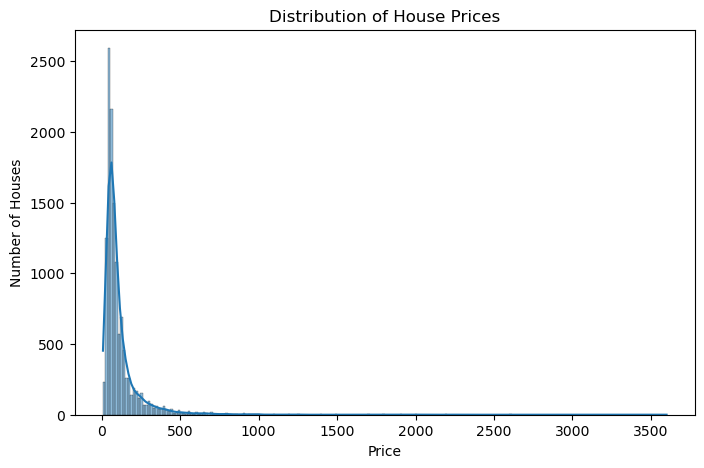

In [18]:
#first graph will be the distribution of our target variable, price.
#Understand house price distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(data['price'], kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Price')
plt.ylabel('Number of Houses')
plt.show()

The price distribution is right-skewed. Most houses have lower prices, while a few expensive properties create extreme high values (outliers).

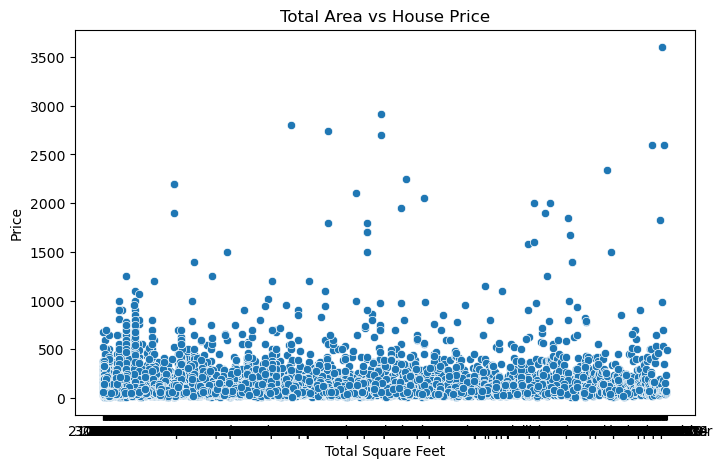

In [19]:
#Area vs Price.
plt.figure(figsize=(8, 5))

sns.scatterplot(x=data['total_sqft'], y=data['price'])

plt.title('Total Area vs House Price')
plt.xlabel('Total Square Feet')
plt.ylabel('Price')
plt.show()

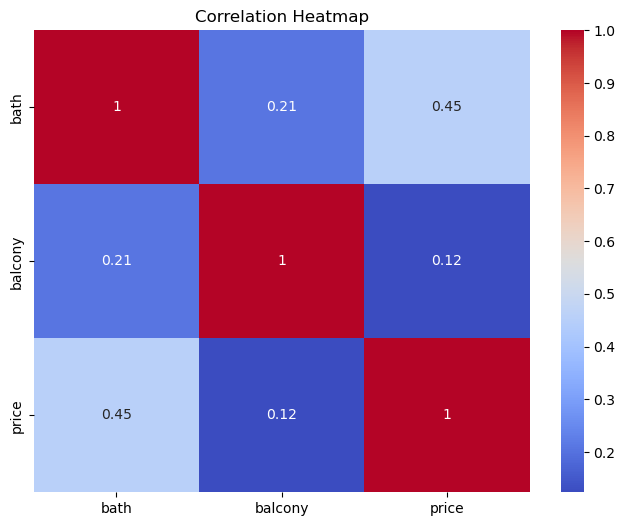

In [20]:
#understanding numeric relationships
plt.figure(figsize=(8, 6))

sns.heatmap(
    data.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

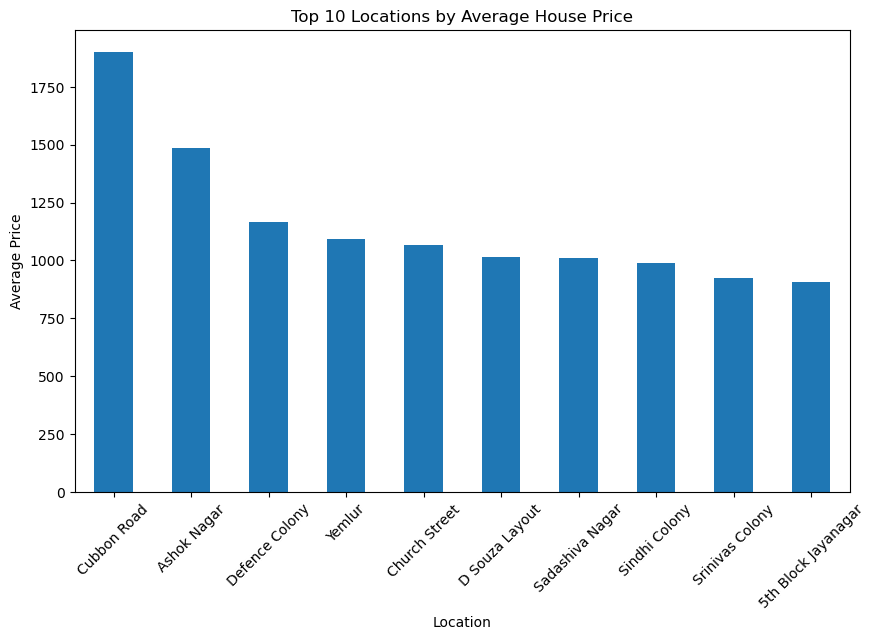

In [21]:
#Location vs Price
location_price = (
    data.groupby('location')['price']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

location_price.plot(kind='bar')

plt.title('Top 10 Locations by Average House Price')
plt.xlabel('Location')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.show()

**Step-4 Feature Engineering**

In [22]:
#Handle missing both bath and size
#Convert size into BHK
data['bhk'] = data['size'].str.extract('(\d+)').astype(float)

In [23]:
data[['size', 'bhk']].head()

,size,bhk
0,2 BHK,2.0
1,4 Bedroom,4.0
2,3 BHK,3.0
3,3 BHK,3.0
4,2 BHK,2.0


In [24]:
data['bhk'].isnull().sum()

np.int64(16)

In [25]:
data['bhk'] = data['bhk'].fillna(data['bhk'].median())

In [26]:
data['bhk'].isnull().sum()

np.int64(0)

In [27]:
data['total_sqft'].head(20)

0     1056
1     2600
2     1440
3     1521
4     1200
5     1170
6     2732
7     3300
8     1310
9     1020
10    1800
11    2785
12    1000
13    1100
14    2250
15    1175
16    1180
17    1540
18    2770
19    1100
Name: total_sqft, dtype: object

In [28]:
data['total_sqft'].dtype

dtype('O')

In [29]:
data['total_sqft'].head(20)

0     1056
1     2600
2     1440
3     1521
4     1200
5     1170
6     2732
7     3300
8     1310
9     1020
10    1800
11    2785
12    1000
13    1100
14    2250
15    1175
16    1180
17    1540
18    2770
19    1100
Name: total_sqft, dtype: object

In [30]:
data['total_sqft'] = pd.to_numeric(data['total_sqft'], errors='coerce')

In [31]:
data['total_sqft'].dtype

dtype('float64')

In [32]:
data['total_sqft'].isnull().sum()

np.int64(246)

In [33]:
data[data['total_sqft'].isnull()][['total_sqft']].head(20)

,total_sqft
30,NaN
56,NaN
81,NaN
122,NaN
137,NaN
165,NaN
188,NaN
224,NaN
410,NaN
549,NaN


In [34]:
data['total_sqft'] = data['total_sqft'].fillna(data['total_sqft'].median())

In [35]:
data['total_sqft'].isnull().sum()

np.int64(0)

In [36]:
data[['bhk', 'total_sqft', 'bath', 'price']].isnull().sum()

bhk            0
total_sqft     0
bath          73
price          0
dtype: int64

In [37]:
data['bath'] = data['bath'].fillna(data['bath'].median())

In [38]:
data['bath'].isnull().sum()

np.int64(0)

In [39]:
data['bhk'] = data['size'].str.extract('(\d+)').astype(float)

In [40]:
data['bhk'] = data['bhk'].fillna(data['bhk'].median())

In [41]:
data['bhk'].isnull().sum()

np.int64(0)

In [42]:
data[['size', 'bhk']].isnull().sum()

size    16
bhk      0
dtype: int64

In [43]:
data = data.drop('size', axis=1)

In [44]:
#again check missing_values
data.isnull().sum()

area_type       0
availability    0
location        0
total_sqft      0
bath            0
balcony         0
price           0
bhk             0
dtype: int64

In [45]:
#Check our engineered columns
data[['bhk', 'total_sqft', 'bath', 'price']].isnull().sum()

bhk           0
total_sqft    0
bath          0
price         0
dtype: int64

In [46]:
data.head()

,area_type,availability,location,total_sqft,bath,balcony,price,bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,1056.0,2.0,1.0,39.07,2.0
1,Plot Area,Ready To Move,Chikka Tirupathi,2600.0,5.0,3.0,120.00,4.0
2,Built-up Area,Ready To Move,Uttarahalli,1440.0,2.0,3.0,62.00,3.0
3,Super built-up Area,Ready To Move,Lingadheeranahalli,1521.0,3.0,1.0,95.00,3.0
4,Super built-up Area,Ready To Move,Kothanur,1200.0,2.0,1.0,51.00,2.0


**Step 5— Preprocessing**

In [47]:
X = data.drop('price', axis=1)
y = data['price']

X = input features used to predict the house price
y = target/output (price)

Machine learning models need the data in a suitable format. The location, area_type and availability columns are categorical, so we can use One-Hot Encoding.

In [48]:
#Separate numerical and categorical features

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_features = ['total_sqft', 'bath', 'balcony', 'bhk']

categorical_features = ['area_type', 'availability', 'location']

In [49]:
#Numerical features
numeric_features = ['total_sqft', 'bath', 'balcony', 'bhk']

In [50]:
#Categorical features
categorical_features = ['area_type', 'availability', 'location']

In [51]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

OneHotEncoder converts categories into numerical indicator columns. handle_unknown="ignore" helps the model handle an unseen category during prediction.

**Step 6— Create the Linear Regression pipeline**

In [52]:
from sklearn.linear_model import LinearRegression

In [53]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [54]:
model

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


**Step 7— Train Test Split**

We divide our data into two parts:
- 80% → Training data: the model learns from this.
- 20% → Testing data: we check how well the model performs on unseen data.

In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [56]:
print(X_train.shape)
print(X_test.shape)

(10200, 7)
(2550, 7)


**Step 8— Train the Linear Regression Model**

In [57]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [58]:
#Then make predictions
y_pred = model.predict(X_test)

Here:
 X_test = houses the model has not seen during training
 y_pred = prices predicted by the model

In [60]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [61]:
y_pred

array([ 64.17381729,  75.14684414,  40.49610077, ...,  29.91726316,
       290.68670753, 259.34429243], shape=(2550,))

In [62]:
print(y_test.head())

4063     36.5
4710     56.0
8848     40.0
5524     95.0
7492    150.0
Name: price, dtype: float64


In [63]:
y = data['price']

In [64]:
y

0         39.07
1        120.00
2         62.00
3         95.00
4         51.00
          ...  
13314    112.00
13315    231.00
13316    400.00
13317     60.00
13318    488.00
Name: price, Length: 12750, dtype: float64

**Step 9 — Model Evaluation**

In [65]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)#Linear Regression model explains approximately 36.6% of the variation in house prices using the features we've provided.

MAE: 46.401444220124255
MSE: 17926.3810990274
RMSE: 133.88943609944513
R² Score: 0.36574906919832284


Linear Regression model is not a strong model yet because the R² score is only 0.366 and the RMSE is quite high.
The Linear Regression model is not highly accurate, so we need to compare it with other regression models to improve performance.

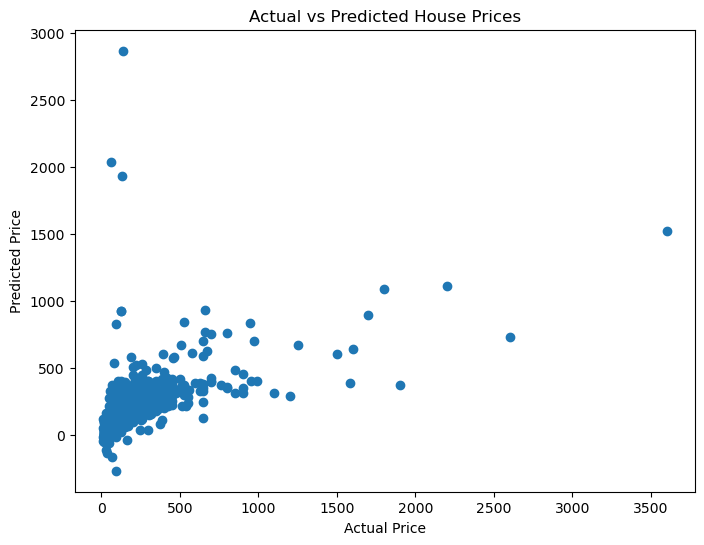

In [66]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

The dots are widely scattered,So Linear Regression model is not predicting house prices very accurately. That is why we should now compare other models.

**Step 10-Model Comparison**

compare Linear Regression, Decision Tree, Random Forest, and Gradient Boosting using MAE, RMSE, and R².

**Decision Tree Regressor**

In [67]:
from sklearn.tree import DecisionTreeRegressor

dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(random_state=42))
])

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

dt_mae = mean_absolute_error(y_test, dt_pred)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_pred))
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree")
print("MAE:", dt_mae)
print("RMSE:", dt_rmse)
print("R² Score:", dt_r2)

Decision Tree
MAE: 38.91622639589169
RMSE: 114.66375183342561
R² Score: 0.5348202679566741


**Random Forest Regressor**

In [68]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R² Score:", rf_r2)

Random Forest
MAE: 33.6209980032884
RMSE: 104.41694815643696
R² Score: 0.6142459629468517


**Gradient Boosting Regressor**

In [69]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(random_state=42))
])

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting")
print("MAE:", gb_mae)
print("RMSE:", gb_rmse)
print("R² Score:", gb_r2)

Gradient Boosting
MAE: 39.539806490242704
RMSE: 100.7353835090332
R² Score: 0.6409684808467752


Gradient Boosting has the best overall performance because
- Lowest RMSE → 100.74
- Highest R² → 0.641
However, Random Forest has the lowest MAE → 33.62.

compared Linear Regression, Decision Tree, Random Forest, and Gradient Boosting. Gradient Boosting performed best overall, achieving an R² score of 0.641 and an RMSE of 100.74. Therefore, I selected Gradient Boosting as the best-performing model

               Model     MAE     RMSE  R2 Score
0  Linear Regression  46.401  133.889     0.366
1      Decision Tree  38.916  114.664     0.535
2      Random Forest  33.621  104.417     0.614
3  Gradient Boosting  39.540  100.735     0.641


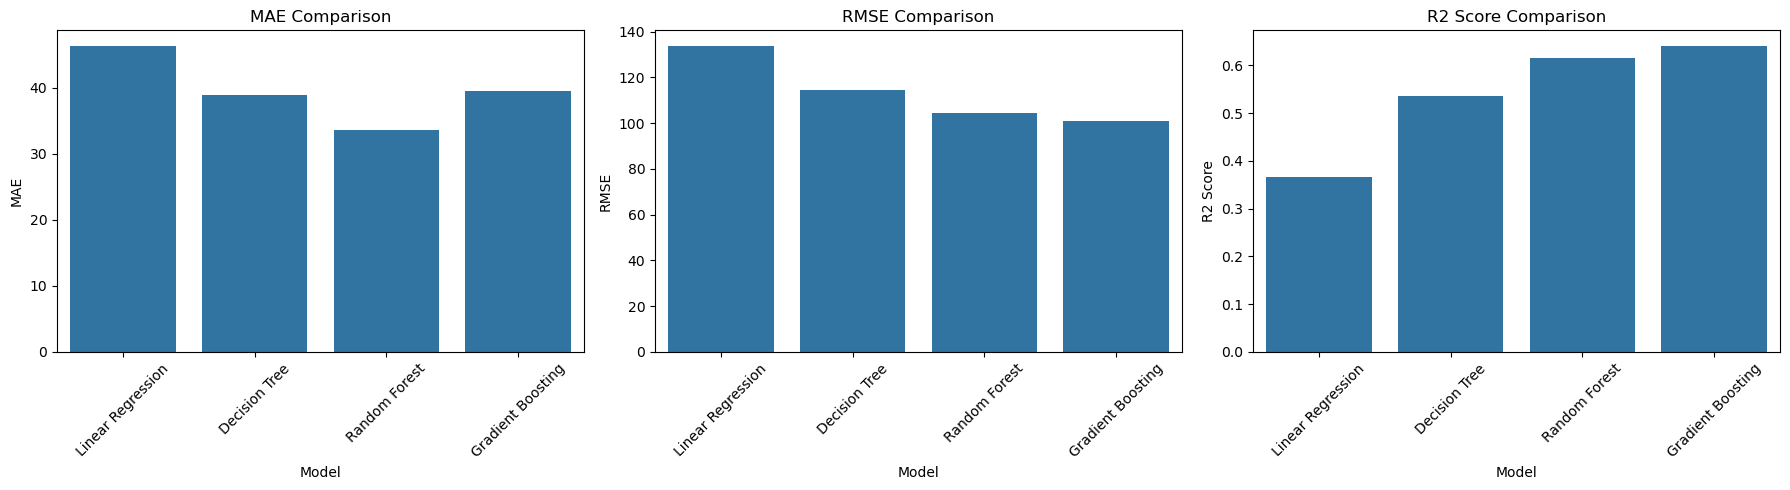

In [71]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [mae, dt_mae, rf_mae, gb_mae],
    "RMSE": [rmse, dt_rmse, rf_rmse, gb_rmse],
    "R2 Score": [r2, dt_r2, rf_r2, gb_r2]
})

print(results.round(3))

metrics = ["MAE", "RMSE", "R2 Score"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric in zip(axes, metrics):
    sns.barplot(
        data=results,
        x="Model",
        y=metric,
        ax=ax
    )
    ax.set_title(f"{metric} Comparison")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Step 11 — Save the Best Model**

In [70]:
import joblib
joblib.dump(gb_model, 'bangalore_house_price_model.pkl')

['bangalore_house_price_model.pkl']